# what in this notebook


##### Install dataset, Data loading ,exoploration,class ditribution,length distibution, 
##### train,validation,test csv file created

# Installing dataset and load datset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns

In [3]:
%pip install datasets

Note: you may need to restart the kernel to use updated packages.


In [4]:
from datasets import load_dataset
print("Import successful")

Import successful


In [5]:
dataset = load_dataset("dair-ai/emotion")

'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/dair-ai/emotion/resolve/cab853a1dbdf4c42c2b3ef2173804746df8825fe/emotion.py
Retrying in 1s [Retry 1/5].


Using the latest cached version of the dataset since dair-ai/emotion couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'split' at C:\Users\jeena\.cache\huggingface\datasets\dair-ai___emotion\split\0.0.0\cab853a1dbdf4c42c2b3ef2173804746df8825fe (last modified on Fri Jun 19 19:02:22 2026).


In [6]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


# Dictionary dataset exploring

In [7]:
type(dataset)

datasets.dataset_dict.DatasetDict

In [8]:
dataset.items()

dict_items([('train', Dataset({
    features: ['text', 'label'],
    num_rows: 16000
})), ('validation', Dataset({
    features: ['text', 'label'],
    num_rows: 2000
})), ('test', Dataset({
    features: ['text', 'label'],
    num_rows: 2000
}))])

In [9]:
print(dataset["train"][0])

{'text': 'i didnt feel humiliated', 'label': 0}


In [10]:
print(dataset["train"][1])

{'text': 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake', 'label': 0}


In [11]:
print(dataset["train"][6:10])

{'text': ['ive been taking or milligrams or times recommended amount and ive fallen asleep a lot faster but i also feel like so funny', 'i feel as confused about life as a teenager or as jaded as a year old man', 'i have been with petronas for years i feel that petronas has performed well and made a huge profit', 'i feel romantic too'], 'label': [5, 4, 1, 2]}


In [12]:
print(dataset["train"].features)

{'text': Value('string'), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}


In [13]:
label_names=dataset["train"].features["label"].names
print(label_names)

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


In [14]:
label_dict=dict(enumerate(dataset["train"].features["label"].names))
print(label_dict)

{0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}


In [15]:
print(dataset["train"])

Dataset({
    features: ['text', 'label'],
    num_rows: 16000
})


# Dictionary to dataframe and data exploration

In [16]:
train_df=dataset["train"].to_pandas()
validation_df=dataset["validation"].to_pandas()
test_df=dataset["test"].to_pandas()


In [17]:
def EDAcomplete(data):
     print("\nShape:\n",data.shape)
     print("\nDatatype:\n",data.dtypes)
     print("\nDimension:\n",data.ndim)
     print("\nINFO:\n",data.info())
     print("\nIndex\n",data.index)
     print("\nSize\n",data.size)
     print("\nFirst Five data (HEAD):\n",data.head())
     print("\nLast Five data (TAIL)\n",data.tail())
     print("\n10 Sample data:\n",data.sample(10))
     print("\nNumber of null values:\n",data.isnull().sum())
     print("\nCount of data:\n",data.value_counts().sum())
     print("\nnumber of unique data\n",data.nunique())
     print("\nNumber of duplicates:\n",data.duplicated().sum())

In [18]:
EDAcomplete(train_df)


Shape:
 (16000, 2)

Datatype:
 text       str
label    int64
dtype: object

Dimension:
 2
<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    16000 non-null  str  
 1   label   16000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 1.7 MB

INFO:
 None

Index
 RangeIndex(start=0, stop=16000, step=1)

Size
 32000

First Five data (HEAD):
                                                 text  label
0                            i didnt feel humiliated      0
1  i can go from feeling so hopeless to so damned...      0
2   im grabbing a minute to post i feel greedy wrong      3
3  i am ever feeling nostalgic about the fireplac...      2
4                               i am feeling grouchy      3

Last Five data (TAIL)
                                                     text  label
15995  i just had a very brief time in the beanbag an...      0
15996  i am no

In [19]:
EDAcomplete(validation_df["text"])


Shape:
 (2000,)

Datatype:
 str

Dimension:
 1
<class 'pandas.Series'>
RangeIndex: 2000 entries, 0 to 1999
Series name: text
Non-Null Count  Dtype
--------------  -----
2000 non-null   str  
dtypes: str(1)
memory usage: 202.0 KB

INFO:
 None

Index
 RangeIndex(start=0, stop=2000, step=1)

Size
 2000

First Five data (HEAD):
 0    im feeling quite sad and sorry for myself but ...
1    i feel like i am still looking at a blank canv...
2                       i feel like a faithful servant
3                    i am just feeling cranky and blue
4    i can have for a treat or if i am feeling festive
Name: text, dtype: str

Last Five data (TAIL)
 1995    im having ssa examination tomorrow in the morn...
1996    i constantly worry about their fight against n...
1997    i feel its important to share this info for th...
1998    i truly feel that if you are passionate enough...
1999    i feel like i just wanna buy any cute make up ...
Name: text, dtype: str

10 Sample data:
 1112               

In [20]:
train_df.columns

Index(['text', 'label'], dtype='str')

In [21]:
train_df.index

RangeIndex(start=0, stop=16000, step=1)

In [22]:
train_df.dtypes

text       str
label    int64
dtype: object

In [23]:
train_df.size

32000

In [24]:
train_df.ndim

2

In [25]:
train_df.head()

,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3


In [26]:
train_df.tail()

,text,label
15995,i just had a very brief time in the beanbag an...,0
15996,i am now turning and i feel pathetic that i am...,0
15997,i feel strong and good overall,1
15998,i feel like this was such a rude comment and i...,3
15999,i know a lot but i feel so stupid because i ca...,0


In [27]:
train_df.sample(10)

,text,label
4900,i didn t feel like i could face the day but i ...,2
11606,i feel like im as useless as dust bunnies,0
7855,i was feeling a bit annoyed but it didnt reall...,3
10125,i flip on reality tv and i feel fantastic tryi...,1
12961,i was feeling pretty cranky and down and all i...,3
3864,i dont say anything because i dont want to cau...,0
4043,i think and feel its funny its sad its weird b...,5
11237,im feeling amused you know that info was poste...,1
995,i should have been depressed but i was actuall...,1
12522,i wonder what life is like for other people pe...,1


In [28]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    16000 non-null  str  
 1   label   16000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 1.7 MB


In [29]:
print(train_df)

                                                    text  label
0                                i didnt feel humiliated      0
1      i can go from feeling so hopeless to so damned...      0
2       im grabbing a minute to post i feel greedy wrong      3
3      i am ever feeling nostalgic about the fireplac...      2
4                                   i am feeling grouchy      3
...                                                  ...    ...
15995  i just had a very brief time in the beanbag an...      0
15996  i am now turning and i feel pathetic that i am...      0
15997                     i feel strong and good overall      1
15998  i feel like this was such a rude comment and i...      3
15999  i know a lot but i feel so stupid because i ca...      0

[16000 rows x 2 columns]


In [30]:
train_df["label"].value_counts()


label
1    5362
0    4666
3    2159
4    1937
2    1304
5     572
Name: count, dtype: int64

In [31]:
train_df["label"].unique()

array([0, 3, 2, 5, 4, 1])

In [32]:
train_df["label"].nunique()

6

In [33]:
each_value_count=train_df["label"].value_counts(normalize=True).sort_index()*100
print(each_value_count)

label
0    29.16250
1    33.51250
2     8.15000
3    13.49375
4    12.10625
5     3.57500
Name: proportion, dtype: float64


In [47]:
validation_df["label"].value_counts()

label
1    704
0    550
3    275
4    212
2    178
5     81
Name: count, dtype: int64

In [35]:
train_df.isnull().sum()

text     0
label    0
dtype: int64

In [36]:
int(train_df.duplicated().sum())

1

count    16000.000000
mean        96.845812
std         55.904953
min          7.000000
25%         53.000000
50%         86.000000
75%        129.000000
max        300.000000
Name: text, dtype: float64


[]

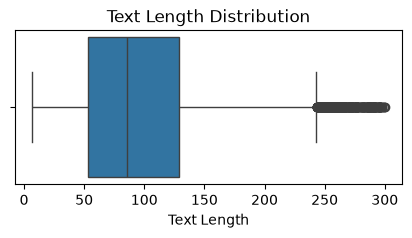

In [37]:
text_length=train_df["text"].str.len()
print(text_length.describe())
plt.figure(figsize=(5,2))
sns.boxplot(x=text_length)
plt.xlabel("Text Length")
plt.title("Text Length Distribution")
plt.plot()

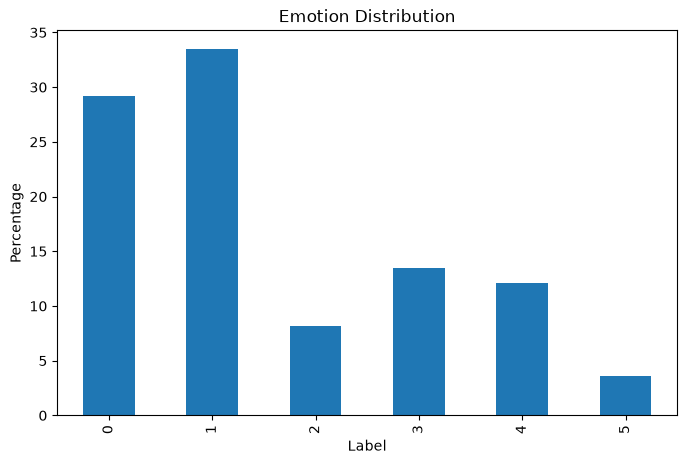

In [38]:

plt.figure(figsize=(8,5))
each_value_count.plot(kind="bar")
plt.title("Emotion Distribution")
plt.xlabel("Label")
plt.ylabel("Percentage")
plt.show()

In [39]:
print(label_names)

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


In [40]:
emotion_label = pd.DataFrame(
    label_dict.items(),
    columns=["label", "emotion"]
)
print(emotion_label)

   label   emotion
0      0   sadness
1      1       joy
2      2      love
3      3     anger
4      4      fear
5      5  surprise


In [41]:
emotion_label.to_csv("emotion_label_hugging",index=False)

In [42]:
train_df.to_csv("train_data.csv",index=False)

In [43]:
validation_df.to_csv("validation_data.csv",index=False)

In [44]:
test_df.to_csv("Testing_data.csv",index=False)